# Task 2.5: Evaluating the hybrid models

Below is the evaluation of the hybrid models defined in `task 1.3` (weighted hybrid) and `task 1.4` (switching hybrid) at their best according to what was tuned there. Everything is as the usual as done in `task 1.1` and `task 2.2`. Run the code blocks from top to botom.

## 1. SETUP

In [62]:
import numpy as np
import pandas as pd
import torch
import os
import matplotlib.pyplot as plt

from metrics import (
    K,
    evaluate_scores,
    evaluate_beyond_accuracy,
    item_popularity,
    short_head_mask
)
from recbole_utils import ROOT, load_split, build_model, score_matrix, top_k

## 2. Loading data, splitting into groups and setting up functions

Belows most of the setup functions and data splits that will be used. It calculates the user profile lengths and splits them into active users (top 20%) and cold users (the remaining 80%) for user group comparisons later down the line. It also precomputes all the evaluation and score results for for following models:
- `Random`
- `Popularity`
- `SLIMElastic`
- `Weighted hybrid`
- `Switching hybrid`

These scores are used a lot down the line so they are all comuted here to prevent redudantly recomputing them

In [63]:
# Load data 
config, dataset, train_data, valid_data, test_data = load_split("SLIMElastic")
UID, IID = dataset.uid_field, dataset.iid_field 
N_USERS = dataset.user_num 
N_ITEMS = dataset.item_num - 1

# extract training interactions for popularity and user profiles
tr_inter = train_data.dataset.inter_feat
tr_u = tr_inter[UID].numpy()
tr_i = tr_inter[IID].numpy() - 1

pop = item_popularity(tr_u, tr_i, N_ITEMS)
history = pd.Series(tr_i).groupby(tr_u).apply(np.asarray).to_dict()

# Load test items dictionary
te = test_data.dataset.inter_feat
test_items = pd.Series(te[IID].numpy() - 1).groupby(te[UID].numpy()).apply(set).to_dict()

# Defining User and Item groups
profile_sizes = pd.Series({u: len(h) for u, h in history.items()})
# Obtaining the top 20% by training interactions
active_threshold = profile_sizes.quantile(0.8)
active_users_mask = profile_sizes >= active_threshold

print(f"Total Users: {N_USERS}, Active Users (>= {active_threshold} items): {active_users_mask.sum()}")

# Item popularity group creation
head_mask = short_head_mask(pop, frac=0.2)
print(f"Short Head Items: {head_mask.sum()}, Long Tail Items: {(~head_mask).sum()}")

item_net, _, _, _, _, _ = build_model("ItemKNN", "ItemKNN", k=100, shrink=100)
slim_net, _, _, _, _, _ = build_model("SLIMElastic", "SLIMElastic", alpha=0.1, l1_ratio=0.1)

def normalise_scores(scores):
    minimum = scores.min(dim=1, keepdim=True).values
    maximum = scores.max(dim=1, keepdim=True).values
    return (scores - minimum) / (maximum - minimum + 1e-12)

def slim_score_fn(interaction):
    return slim_net.full_sort_predict(interaction).view(len(interaction), -1)

def item_score_fn(interaction):
    return item_net.full_sort_predict(interaction).view(len(interaction), -1)

# Weighted hybrid score generator (task 1.3) (ItemKNN ~0.4, SLIMElastic ~0.6)
weights = [0.4, 0.6]
def weighted_hybrid_scores_fn(interaction):
    item_scores = normalise_scores(item_net.full_sort_predict(interaction).view(len(interaction), -1))
    slim_scores = normalise_scores(slim_net.full_sort_predict(interaction).view(len(interaction), -1))
    return weights[0] * item_scores + weights[1] * slim_scores

# Switching hybrid score Generator (task 1.4) (-1 which means 100% SLIMElastic and 0% Popularity)
item_counts_tensor = torch.from_numpy(pop).float()
best_threshold = -1
def switching_hybrid_scores_fn(interaction):
    personalized = slim_net.full_sort_predict(interaction).view(len(interaction), -1)
    
    popularity_padded = torch.cat([
        torch.tensor([0.0], device=personalized.device), 
        item_counts_tensor.to(personalized.device, dtype=personalized.dtype)
    ])

    popularity = popularity_padded.unsqueeze(0).expand_as(personalized)
    
    user_ids = interaction[UID].long().cpu()
    user_profile_lengths = torch.tensor([len(history.get(u.item(), [])) for u in user_ids])
    sparse = (user_profile_lengths <= best_threshold).to(personalized.device)
    
    return torch.where(sparse[:, None], popularity, personalized)

_, ref_database, ref_train,ref_valid, ref_test = load_split("Pop")
popularity = np.bincount(ref_train.dataset.inter_feat[dataset.iid_field].numpy(), minlength=N_ITEMS + 1).astype(np.float32)
_rng = np.random.default_rng(2020)

BASELINE_SCORES = {
    "Popularity": lambda inter: torch.from_numpy(np.tile(popularity, (len(inter), 1))),
    "Random": lambda inter: torch.from_numpy(_rng.random((len(inter), N_ITEMS + 1), dtype=np.float32))
}

all_evaluation_models = {
    "Popularity": BASELINE_SCORES["Popularity"],
    "Random": BASELINE_SCORES["Random"],
    "SLIMElastic": slim_score_fn,
    "itemKNN": item_score_fn,
    "Weighted_Hybrid": weighted_hybrid_scores_fn,
    "Switching_Hybrid": switching_hybrid_scores_fn,
}

model_eval_cache = {}
for model_name, score_fn in all_evaluation_models.items():
    scores, t_items = score_matrix(score_fn, test_data, N_USERS, N_ITEMS + 1, UID)
    eval_res = evaluate_scores(scores, t_items, ks=(K,))
    model_eval_cache[model_name] = {
        "scores": scores,
        "t_items": t_items,
        "eval_res": eval_res,
        "per_user": eval_res["per_user"]
    }

Total Users: 944, Active Users (>= 137.60000000000002 items): 189
Short Head Items: 336, Long Tail Items: 1346


## 3. Accuracy metrics comparisons

In this section the user groups are evaluated on different metrics.

In [64]:
results_summary = []

for model_name, res in model_eval_cache.items():    
    pu_df = res["per_user"]
    
    eval_users = pu_df.index.to_numpy()
    is_active = active_users_mask.reindex(eval_users, fill_value=False).to_numpy()
    
    ndcg_col = f"ndcg@{K}"
    recall_col = f"recall@{K}"
    hit_col = f"hit@{K}"
    mrr_col = f"mrr@{K}"
    prec_col = f"precision@{K}"
    map_col = f"map@{K}"
    f1_col = f"f1@{K}"

    
    results_summary.append({
        "Model": model_name,
        "Group": "All Users",
        "NDCG@10": pu_df[ndcg_col].mean(),
        "Recall@10": pu_df[recall_col].mean(),
        "Hit@10": pu_df[hit_col].mean(),
        "MRR@10": pu_df[mrr_col].mean(),
        "precision@10": pu_df[prec_col].mean(),
        "map@10": pu_df[map_col].mean(),
        "f1@10": pu_df[f1_col].mean()
    })
    results_summary.append({
        "Model": model_name,
        "Group": "Active Users (Top 20%)",
        "NDCG@10": pu_df.loc[is_active, ndcg_col].mean(),
        "Recall@10": pu_df.loc[is_active, recall_col].mean(),
        "Hit@10": pu_df.loc[is_active, hit_col].mean(),
        "MRR@10": pu_df.loc[is_active, mrr_col].mean(),
        "precision@10": pu_df.loc[is_active, prec_col].mean(),
        "map@10": pu_df.loc[is_active, map_col].mean(),
        "f1@10": pu_df.loc[is_active, f1_col].mean()
    })
    results_summary.append({
        "Model": model_name,
        "Group": "Cold/Low-Activity Users",
        "NDCG@10": pu_df.loc[~is_active, ndcg_col].mean(),
        "Recall@10": pu_df.loc[~is_active, recall_col].mean(),
        "Hit@10": pu_df.loc[~is_active, hit_col].mean(),
        "MRR@10": pu_df.loc[~is_active, mrr_col].mean(),
        "precision@10": pu_df.loc[~is_active, prec_col].mean(),
        "map@10": pu_df.loc[~is_active, map_col].mean(),
        "f1@10": pu_df.loc[~is_active, f1_col].mean()
    })

# 5. Display Group-Sliced Performance Table
summary_df = pd.DataFrame(results_summary)

In [65]:
# Porting it to CSV
output_dir = "results/task_2_5"
os.makedirs(output_dir, exist_ok=True)

raw_csv_path = os.path.join(output_dir, "group_sliced_summary.csv")

summary_df.to_csv(raw_csv_path, index=False)
display(summary_df)

,Model,Group,NDCG@10,Recall@10,Hit@10,MRR@10,precision@10,map@10,f1@10
0,Popularity,All Users,0.141554,0.127425,0.575822,0.266296,0.102863,0.069735,0.091466
1,Popularity,Active Users (Top 20%),0.246080,0.083733,0.857143,0.494048,0.227513,0.127962,0.120124
2,Popularity,Cold/Low-Activity Users,0.115353,0.138377,0.505305,0.209207,0.071618,0.055140,0.084282
3,Random,All Users,0.007999,0.006480,0.068929,0.019505,0.007529,0.002488,0.005906
4,Random,Active Users (Top 20%),0.020158,0.007264,0.174603,0.058228,0.019577,0.006273,0.010447
5,Random,Cold/Low-Activity Users,0.004951,0.006283,0.042440,0.009798,0.004509,0.001540,0.004767
6,SLIMElastic,All Users,0.310771,0.264639,0.803818,0.511346,0.207105,0.191785,0.188576
7,SLIMElastic,Active Users (Top 20%),0.497048,0.167847,0.994709,0.819875,0.442328,0.333497,0.238933
8,SLIMElastic,Cold/Low-Activity Users,0.264079,0.288901,0.755968,0.434010,0.148143,0.156263,0.175954
9,itemKNN,All Users,0.281920,0.240213,0.792153,0.482669,0.183033,0.169232,0.168307


What becomes very clear from these results that `Active Users` have significantly better scores than `Cold Users` for all models. This in itself is pretty self explanatory since they have more data to work with. The `weighted hybrid` model slightly outperforms the other models here when it comes to `Cold Users` compared to both `switching hybrid` and `SLIMElastic`. However from the tuning done on `switching hybrid` it is basically just `SLIMElastic`. Their scores are identical in all aspects. That only leaves comparison with `weighted hybrid` of any interest.   

## 4. Beyond accuracy hybrid analysis

In [ ]:
item_feat = dataset.get_item_feature()
if "genre" in item_feat:
    genres = item_feat["genre"].cpu().numpy()
    genres = genres[1:]
else:
    n_genres = 18
    genres = np.eye(N_ITEMS + 1)[:N_ITEMS + 1]

beyond_results_summary = []

for model_name, res in model_eval_cache.items():
    if model_name == "Random":
        continue
    pu_df = res["per_user"]
    eval_users = pu_df.index.to_numpy()

    recs = top_k(res["scores"], eval_users, K + 1)
    recs = np.array([[item for item in r if item > 0][:K] for r in recs])

    user_histories = [history.get(u, np.array([], dtype=int)) for u in eval_users]

    is_active = active_users_mask.reindex(eval_users, fill_value=False).to_numpy()
    user_groups = {"Active Users (Top 20%)": is_active, "Cold/Low-Activity Users": ~is_active}

    for group_name, mask in user_groups.items():
        if mask.sum() == 0:
            continue 

        group_recs = recs[mask]
        group_histories = [user_histories[i] for i, m in enumerate(mask) if m]
        group_accuracy = pu_df[f"ndcg@{K}"].to_numpy()[mask]

        beyond_summary, _ = evaluate_beyond_accuracy(
            recs=group_recs,
            histories=group_histories,
            genres=genres,
            pop=pop,
            n_users=N_USERS,
            user_groups=None,
            accuracy=group_accuracy
        )

        summary_dict = beyond_summary.to_dict()
        summary_dict["Model"] = model_name 
        summary_dict["Group"] = group_name
        beyond_results_summary.append(summary_dict)

beyond_summary_df = pd.DataFrame(beyond_results_summary).set_index(["Model", "Group"])
display(beyond_summary_df)

beyond_csv_path = os.path.join(output_dir, "beyond_accuracy_summary.csv")
beyond_summary_df.to_csv(beyond_csv_path)

,ild@10,novelty@10,mc_kl@10,upd@10,arp@10,aplt@10,coverage@10,gini@10,exposure_head@10,exposure_tail@10,exposure_ratio@10,gru_active_users,gru_cold_users
Model,,,,,,,,,,,,,
Popularity,1.0,3.471840,4.523356,0.078032,0.127123,0.365429,0.036861,0.987495,8.075990,1.167194,6.919147,0.130727,0.130727
SLIMElastic,1.0,3.649298,4.526475,0.114512,0.117334,0.458112,0.197979,0.928490,7.009738,1.433361,4.890419,0.232970,0.232970
itemKNN,1.0,3.608693,4.519749,0.105396,0.121387,0.436055,0.153983,0.945038,7.251740,1.372951,5.281864,0.198814,0.198814
Weighted_Hybrid,1.0,3.619299,4.522888,0.110472,0.119705,0.447932,0.181332,0.935893,7.132710,1.402664,5.085116,0.233439,0.233439
Switching_Hybrid,1.0,3.649298,4.526475,0.114512,0.117334,0.458112,0.197979,0.928490,7.009738,1.433361,4.890419,0.232970,0.232970


## 5. Item groups accuracy hybrid analysis

In [67]:
head_mask = short_head_mask(pop, frac=0.2)

item_group_results = []

for model_name, res in model_eval_cache.items():

    head_hits, head_total = 0, 0
    tail_hits, tail_total = 0, 0

    for u, items in res["t_items"].items():
        s = res["scores"][u]
        candidates = np.flatnonzero(np.isfinite(s))
        if len(candidates) == 0 or not items:
            continue

        k_recs = np.argsort(-s[candidates], kind="stable")[:K]
        rec_items = candidates[k_recs]
        rec_set = set(rec_items)

        for item in items:
            is_head = head_mask[item]
            hit = int(item in rec_set)
            if is_head:
                head_hits += hit
                head_total += 1
            else:
                tail_hits += hit 
                tail_total += 1

    item_group_results.append({
        "Model": model_name,
        "Head Hit Rate@10": head_hits / head_total if head_total > 0 else 0.0,
        "Tail Hit Rate@10": tail_hits / tail_total if tail_total > 0 else 0.0,
        "Head Test Items": head_total,
        "Tail Test Items": tail_total
    })

item_group_summary_df = pd.DataFrame(item_group_results).set_index("Model")
display(item_group_summary_df)

item_group_csv_path = os.path.join(output_dir, "item_group_summary.csv")
item_group_summary_df.to_csv(item_group_csv_path)

,Head Hit Rate@10,Tail Hit Rate@10,Head Test Items,Tail Test Items
Model,,,,
Popularity,0.153907,0.066240,3814,5782
Random,0.006817,0.007783,3814,5782
SLIMElastic,0.272942,0.157731,3814,5782
itemKNN,0.245412,0.136631,3814,5782
Weighted_Hybrid,0.273466,0.157039,3814,5782
Switching_Hybrid,0.272942,0.157731,3814,5782


## 6. Comparisons to baselines

In [69]:
baseline_per_user_results = {}
baseline_summary_rows = []

for model_name, res in model_eval_cache.items():
    pu_df = res["per_user"]
    baseline_per_user_results[model_name] = pu_df

    metrics_at_k = res["eval_res"]["topk"][f"@{K}"]
    baseline_summary_rows.append({
        "model": model_name,
        f"ndcg@{K}": metrics_at_k["ndcg"],
        f"recall@{K}": metrics_at_k["recall"],
        f"precision@{K}": metrics_at_k["precision"],
        f"hit@{K}": metrics_at_k["hit"],
        f"mrr@{K}": metrics_at_k["mrr"],
        "auc": res["eval_res"]["auc"]
    })

baseline_summary_df = pd.DataFrame(baseline_summary_rows).set_index("model")    
display(baseline_summary_df)

,ndcg@10,recall@10,precision@10,hit@10,mrr@10,auc
model,,,,,,
Popularity,0.141554,0.127425,0.102863,0.575822,0.266296,0.858903
Random,0.007999,0.006480,0.007529,0.068929,0.019505,0.496683
SLIMElastic,0.310771,0.264639,0.207105,0.803818,0.511346,0.919954
itemKNN,0.281920,0.240213,0.183033,0.792153,0.482669,0.924002
Weighted_Hybrid,0.312391,0.265060,0.206893,0.808059,0.518038,0.928839
Switching_Hybrid,0.310771,0.264639,0.207105,0.803818,0.511346,0.919954


In [70]:
from scipy.stats import wilcoxon

def holm_correction(pvalues):
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(p)
    out[order] = adjusted
    return out


metrics_to_compare = [f"ndcg@{K}", f"recall@{K}", f"precision@{K}", f"hit@{K}", f"mrr@{K}", "auc"]

sig_rows = []

for name in baseline_summary_df.index:
    if name == "Popularity":
        continue
    row = {"model": name}

    for m in metrics_to_compare:
        pop_val = baseline_summary_df.loc["Popularity", m]
        model_val = baseline_summary_df.loc[name, m]
        row[f"Δ{m.upper()} vs Pop"] = (model_val / pop_val) - 1 if pop_val != 0 else np.nan
        row[f"p({m}) vs Pop"] = wilcoxon(
            baseline_per_user_results[name][m],
            baseline_per_user_results["Popularity"][m]
        ).pvalue

    sig_rows.append(row)

sig_df = pd.DataFrame(sig_rows).set_index("model")

p_columns = [c for c in sig_df.columns if c.startswith("p(")]
flat_p = sig_df[p_columns].to_numpy().ravel()
valid_mask = ~np.isnan(flat_p)
flat_p[valid_mask] = holm_correction(flat_p[valid_mask])
sig_df[p_columns] = flat_p.reshape(sig_df[p_columns].shape)

formatting_dict = {c: "{:+.0%}" for c in sig_df.columns if c.startswith("Δ")}
formatting_dict.update({c: "{:.1e}" for c in p_columns})

display(sig_df.style.format(formatting_dict, na_rep="–"))

sig_df.to_csv(os.path.join(output_dir, "baseline_comparisons.csv"))

,ΔNDCG@10 vs Pop,p(ndcg@10) vs Pop,ΔRECALL@10 vs Pop,p(recall@10) vs Pop,ΔPRECISION@10 vs Pop,p(precision@10) vs Pop,ΔHIT@10 vs Pop,p(hit@10) vs Pop,ΔMRR@10 vs Pop,p(mrr@10) vs Pop,ΔAUC vs Pop,p(auc) vs Pop
model,,,,,,,,,,,,
Random,-94%,2.9e-86,-95%,1.1e-82,-93%,7.0e-87,-88%,3.4e-99,-93%,3.8e-78,-42%,1.5e-152
SLIMElastic,+120%,8.7e-87,+108%,1.9e-64,+101%,1.6e-78,+40%,2.0e-36,+92%,5.7e-58,+7%,2.1e-124
itemKNN,+99%,3.6e-71,+89%,4.6e-53,+78%,9.0e-63,+38%,2.8e-33,+81%,3.3e-45,+8%,5.2e-134
Weighted_Hybrid,+121%,6.0e-90,+108%,2.3e-68,+101%,4.9e-79,+40%,1.1e-38,+95%,1.2e-61,+8%,1.0e-142
Switching_Hybrid,+120%,8.7e-87,+108%,1.9e-64,+101%,1.6e-78,+40%,2.0e-36,+92%,5.7e-58,+7%,2.1e-124


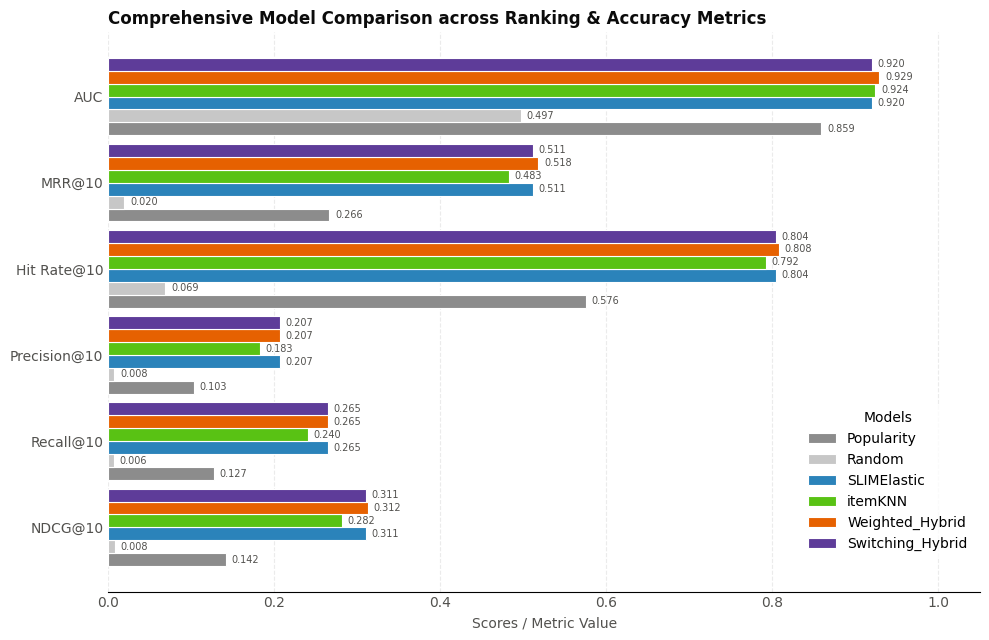

In [71]:
INK, MUTED = "#0b0b0b", "#52514e"
metric_labels = [f"NDCG@{K}", f"Recall@{K}", f"Precision@{K}", f"Hit Rate@{K}", f"MRR@{K}", "AUC"]

plot_df = baseline_summary_df[metrics_to_compare].copy()
models = plot_df.index.tolist()

MODEL_COLOURS = {
    "Popularity": "#8c8c8c",       # Neutral Dark Gray
    "Random": "#c7c7c7",           # Neutral Light Gray
    "SLIMElastic": "#2b83ba",      # Blue
    "itemKNN": "#59c214",          # Green
    "Weighted_Hybrid": "#e66101",  # Orange
    "Switching_Hybrid": "#5e3c99", # Purple
}

default_colours = plt.cm.tab10.colors 

y_positions = np.arange(len(metrics_to_compare))
width = 0.15

fig, ax = plt.subplots(figsize=(10, 6.5))

for i, model_name in enumerate(models):
    values = plot_df.loc[model_name].values
    offset = (i - len(models) / 2) * width + width / 2
    colour = MODEL_COLOURS.get(model_name, default_colours[i % len(default_colours)])

    bars = ax.barh(y_positions + offset, values, height=width, label=model_name, color=colour, edgecolor="white", linewidth=0.8)

    for bar in bars:
        width_val = bar.get_width()
        ax.annotate(
            f"{width_val:.3f}",
            xy=(width_val, bar.get_y() + bar.get_height() / 2),
            xytext=(4, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=7,
            color=MUTED,
            fontweight="medium"
        )

ax.set_yticks(y_positions)
ax.set_yticklabels(metric_labels, color=INK, fontweight="medium")
ax.set_xlabel("Scores / Metric Value", color=MUTED)
ax.set_title(f"Comprehensive Model Comparison across Ranking & Accuracy Metrics", loc="left", color=INK, fontweight="bold")
ax.grid(axis="x", color="0.92", linestyle="--")
ax.set_axisbelow(True)

ax.set_xlim(0, 1.05)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, length=0)

ax.legend(title="Models", frameon=True, facecolor="white", edgecolor="none", loc="lower right", bbox_to_anchor=(1.0, 0.05))

plt.tight_layout()

plt.savefig(os.path.join(output_dir, "hybrids_vs_baselines_all_metrics.png"), dpi=200)
plt.show()